## Import packages & load data

In [2]:
#Import
from pathlib import Path as FilePath
from collections import Counter
import pandas as pd
from helpers import *
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Load data
clean_data = pd.read_excel("customers_sales_with_dxf_data.xlsx")
clean_data.head(5)

,customer_name,customer_branch,file_name,order_quantity,customer_name_original,customer_branch_original,bounding_box_width,bounding_box_height,bounding_box_area,cutting_length,num_holes,rectangularity,num_pierce_points
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,MetalForm SA,Frankfurt Branch,1600.219048,305.140135,488291.056038,3438.024977,0,0.082199,1
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,AutoParts AG,Munich Branch,853.830000,333.401400,284668.117362,3217.207505,5,0.724271,6
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,PrecisionCut GmbH,Stuttgart Branch,164.000000,145.120000,23799.680000,1742.517642,7,0.600032,8
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,PrecisionCut GmbH,Stuttgart Branch,193.800891,138.442589,26830.297074,1302.774283,2,0.685885,3
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,AutoParts AG,Berlin Branch,937.150697,74.006665,69355.398059,2764.783512,11,0.865878,12


## Relevant measures that should be checked for outliers
#### (findings of univariate, bivariate & multivariate analysis):
1. order quantity
2. bounding box height
3. cutting length
4. bounding box area
5. number of holes
6. rectangularity?

## 1. Check outliers of order quantity

                order quantity
q25                     4000.0
q75                     9050.0
min                      500.0
max                    19700.0
range                  19200.0
iqr                     5050.0
n_outliers_iqr             6.0


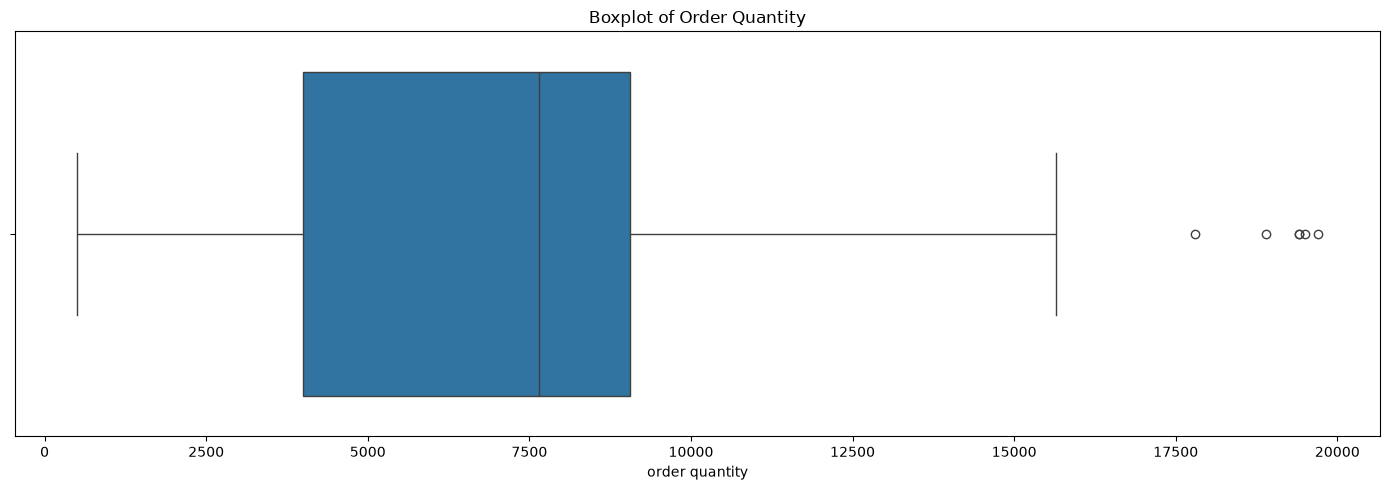

In [3]:
# Calculate quantity statistics
quantities = clean_data["order_quantity"].dropna()
q1, q3 = quantities.quantile(0.25), quantities.quantile(0.75)
iqr = q3 - q1

quantity_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": quantities.min(),
    "max": quantities.max(),
    "range": quantities.max() - quantities.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((quantities < q1 - 1.5 * iqr) | (quantities > q3 + 1.5 * iqr)).sum(),
})

print(round(quantity_statistics.to_frame(name="order quantity"), 2))


# Visualize the order quantity statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=quantities, ax=ax)
ax.set_title("Boxplot of Order Quantity")
ax.set_xlabel("order quantity")

plt.tight_layout()
plt.show()



In [4]:
for i, quant in enumerate(quantities):
    if (quant < q1 - 1.5 * iqr) or (quant > q3 + 1.5 * iqr):
        print(
            "Customer Name:", clean_data["customer_name"].iloc[i], "\n",
            "Customer Branch:", clean_data["customer_branch"].iloc[i], "\n",
            "File Name:", clean_data["file_name"].iloc[i], "\n"
        )

Customer Name: TechFab Industries 
 Customer Branch: Hamburg Branch 
 File Name: Geo (30).DXF 

Customer Name: TechFab Industries 
 Customer Branch: Hamburg Branch 
 File Name: Geo (32).DXF 

Customer Name: TechFab Industries 
 Customer Branch: Hamburg Branch 
 File Name: Geo (35).DXF 

Customer Name: TechFab Industries 
 Customer Branch: Hamburg Branch 
 File Name: Geo (60).DXF 

Customer Name: TechFab Industries 
 Customer Branch: Hamburg Branch 
 File Name: Geo (61).DXF 

Customer Name: TechFab Industries 
 Customer Branch: Hamburg Branch 
 File Name: Geo (63).DXF 



We directly see a clear structure in the outlier output. All outliers are from the customer "TechFab Industries" and their branch in Hamburg. This matches quite well the customer structure results from the bi- and multivariate analysis which alreasy showed us, that this customer has a substantially larger demand for there parts. Therefore these results are interesting but not at all concerning regarding data quality.

## 2. Check outliers of bounding box height

                bounding box height
q25                           70.31
q75                          312.83
min                           12.11
max                         1193.26
range                       1181.15
iqr                          242.52
n_outliers_iqr                 7.00


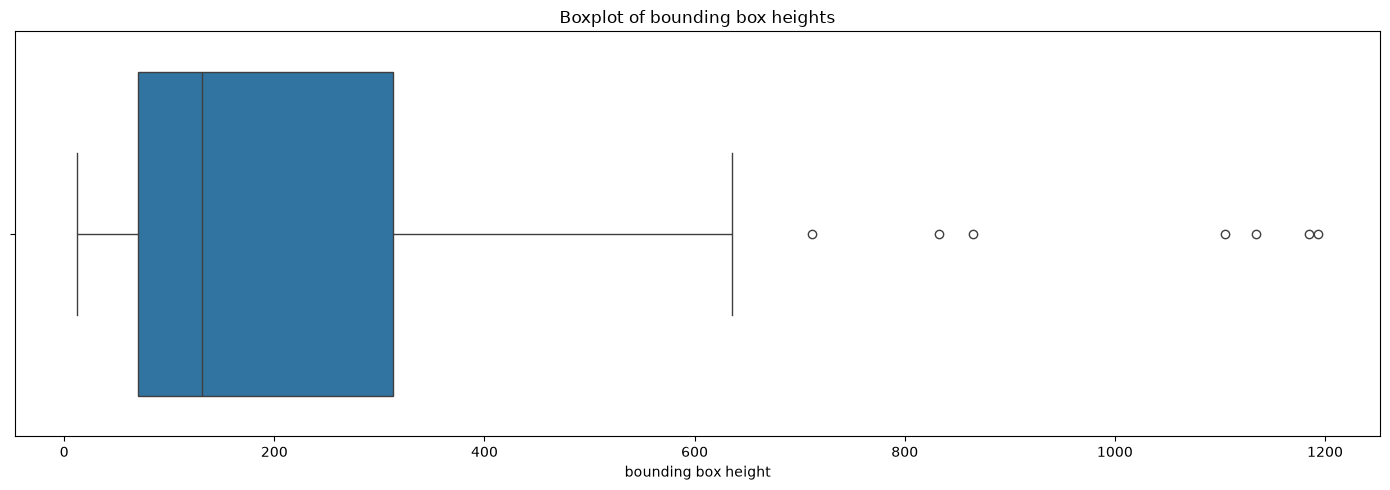

In [5]:
# Calculate height statistics
heights = clean_data["bounding_box_height"].dropna()
q1, q3 = heights.quantile(0.25), heights.quantile(0.75)
iqr = q3 - q1

height_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": heights.min(),
    "max": heights.max(),
    "range": heights.max() - heights.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((heights < q1 - 1.5 * iqr) | (heights > q3 + 1.5 * iqr)).sum(),
})

print(round(height_statistics.to_frame(name="bounding box height"), 2))


# Visualize the height statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=heights, ax=ax)
ax.set_title("Boxplot of bounding box heights")
ax.set_xlabel("bounding box height")

plt.tight_layout()
plt.show()

Some outliers are significantly higher than the average, so we should check the DXF plots for further clarification.

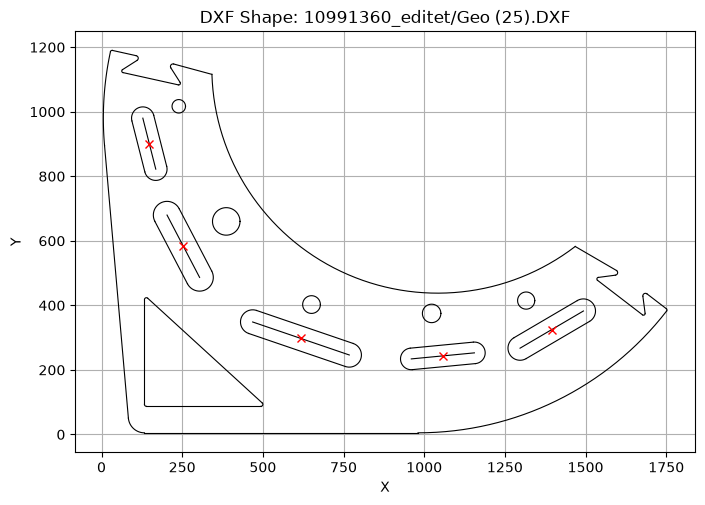

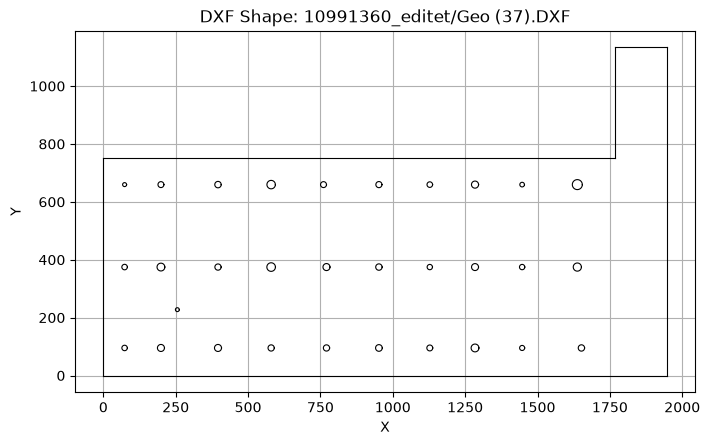

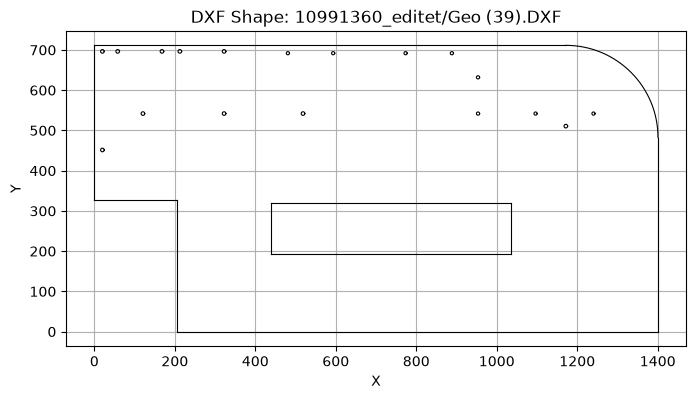

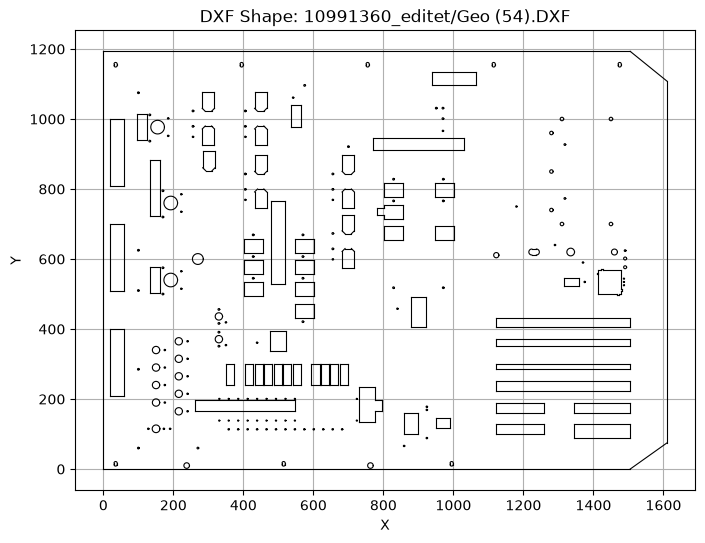

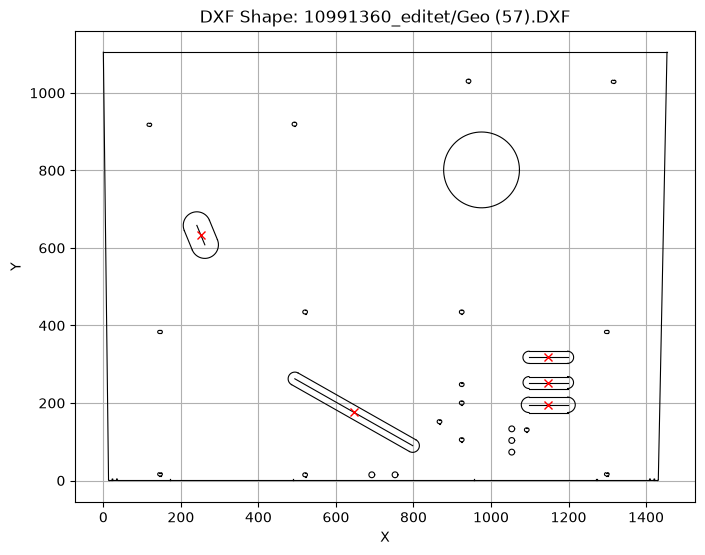

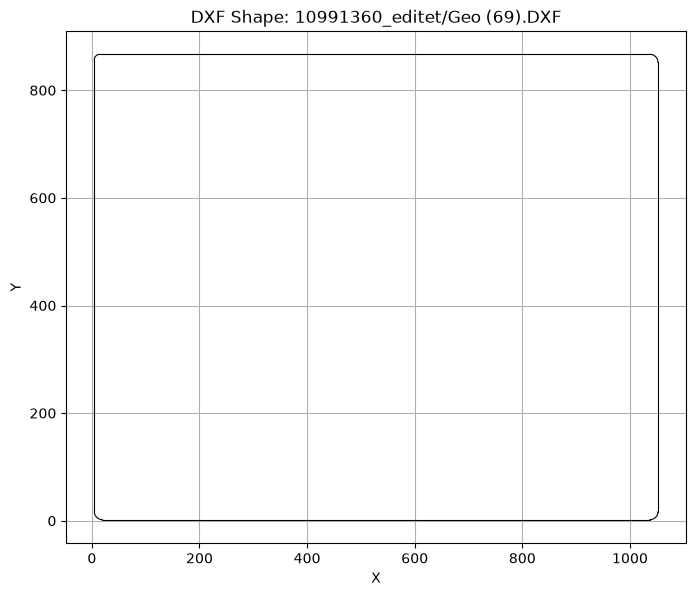

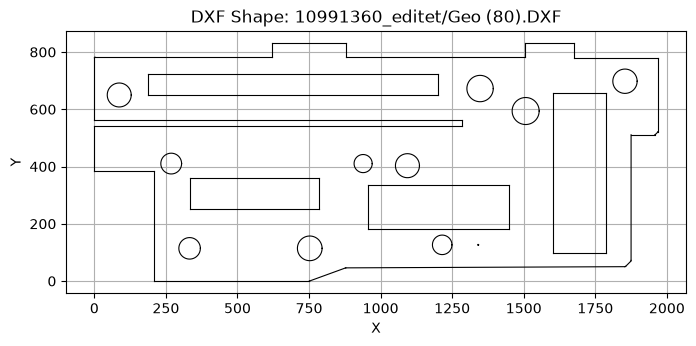

In [6]:
for i, height in enumerate(heights):
    if (height < q1 - 1.5 * iqr) or (height > q3 + 1.5 * iqr):
        plot_dxf("10991360_editet/" + clean_data["file_name"].iloc[i])

As the plots show, all outliers are legit DXF geometries.

## 2. Check outliers of cutting length

                cutting length
q25                     775.30
q75                    3711.43
min                     100.96
max                   26007.87
range                 25906.91
iqr                    2936.13
n_outliers_iqr            6.00


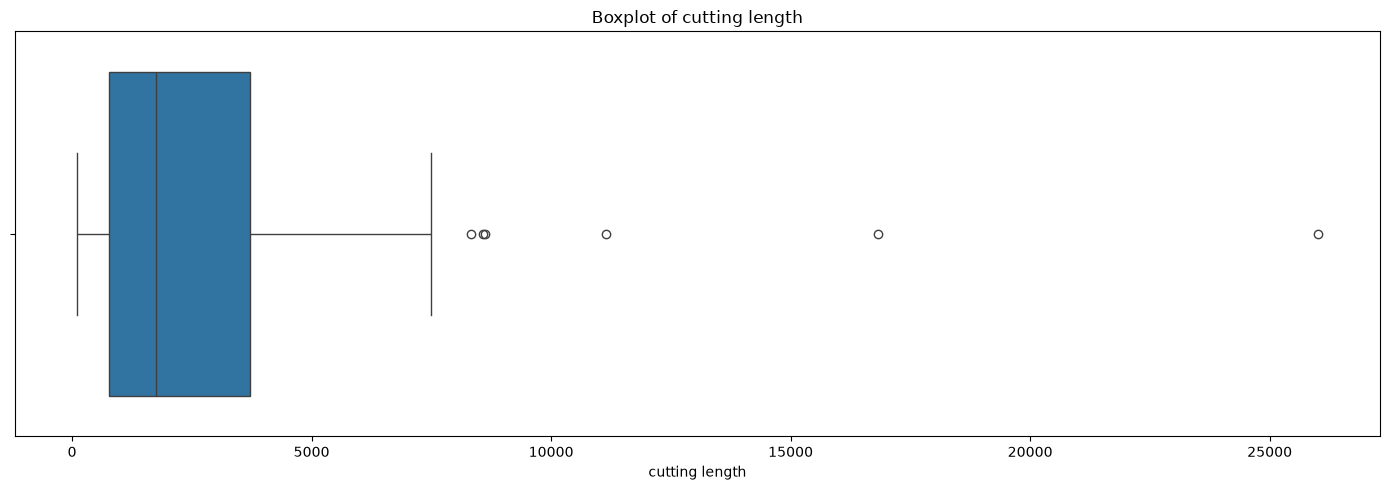

In [7]:
# Calculate cutting length statistics
cutting_lengths = clean_data["cutting_length"].dropna()
q1, q3 = cutting_lengths.quantile(0.25), cutting_lengths.quantile(0.75)
iqr = q3 - q1

cutting_length_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": cutting_lengths.min(),
    "max": cutting_lengths.max(),
    "range": cutting_lengths.max() - cutting_lengths.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((cutting_lengths < q1 - 1.5 * iqr) | (cutting_lengths > q3 + 1.5 * iqr)).sum(),
})

print(round(cutting_length_statistics.to_frame(name="cutting length"), 2))


# Visualize the cutting length statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=cutting_lengths, ax=ax)
ax.set_title("Boxplot of cutting length")
ax.set_xlabel("cutting length")

plt.tight_layout()
plt.show()

Here the outliers are even wider apart from eath other and are substantialy different from the average.

Hence we should have a closer look at the exact geometries.

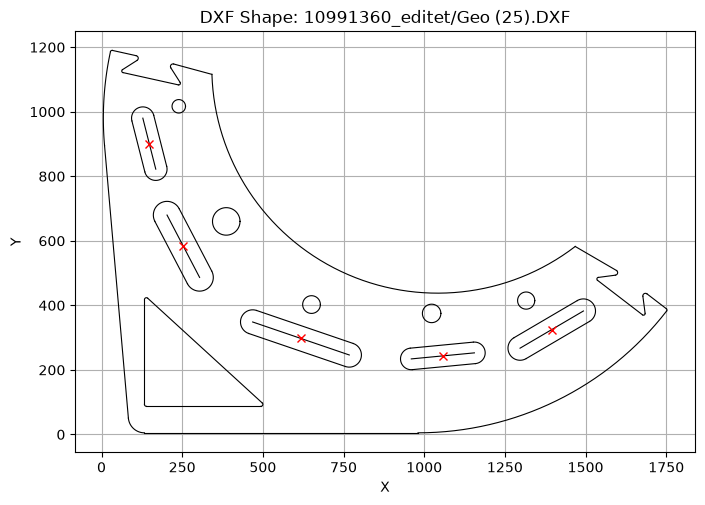

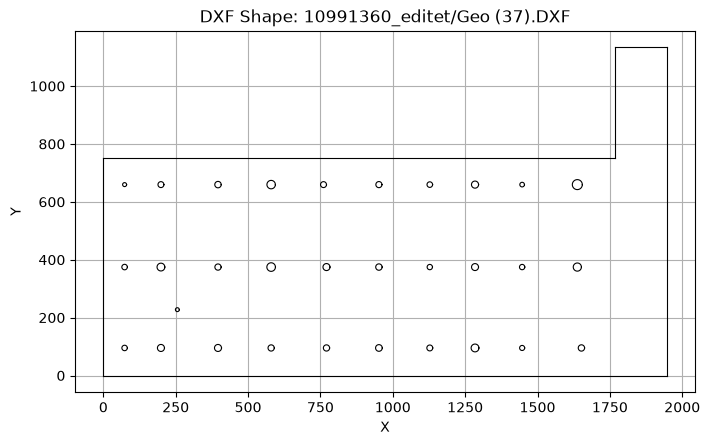

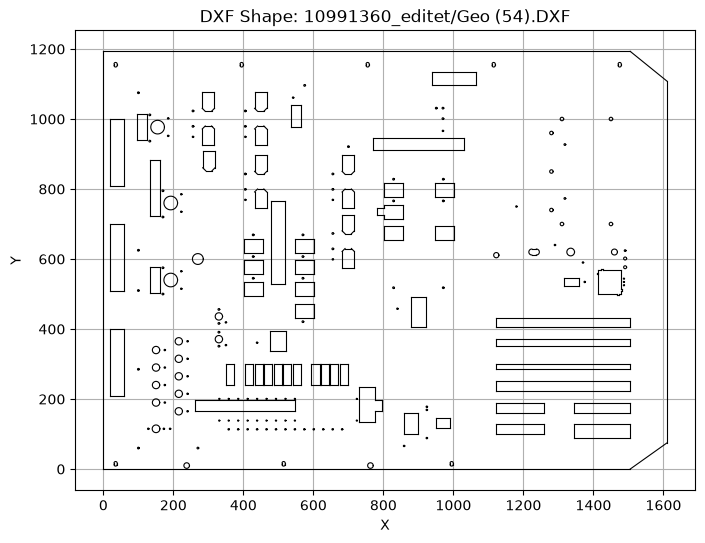

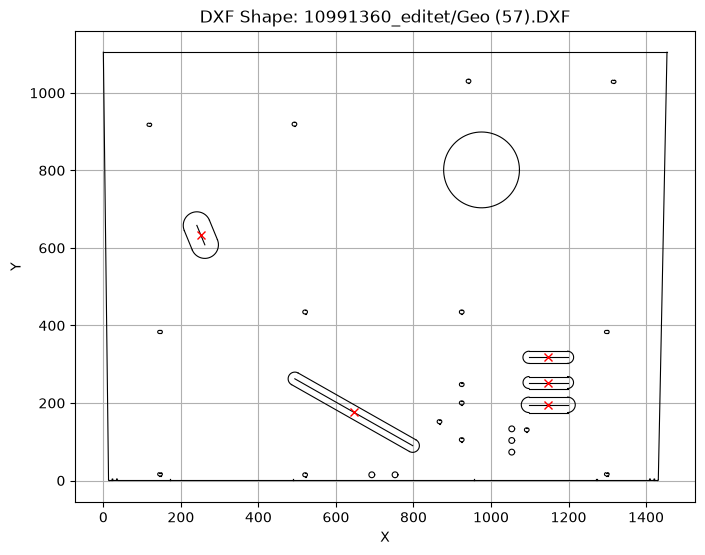

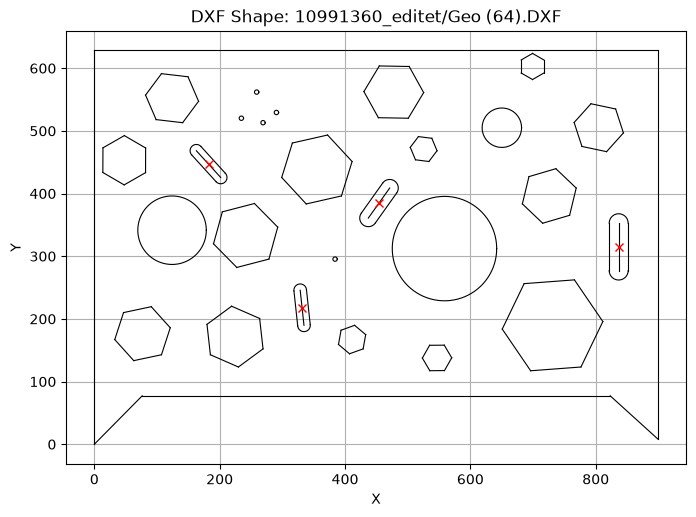

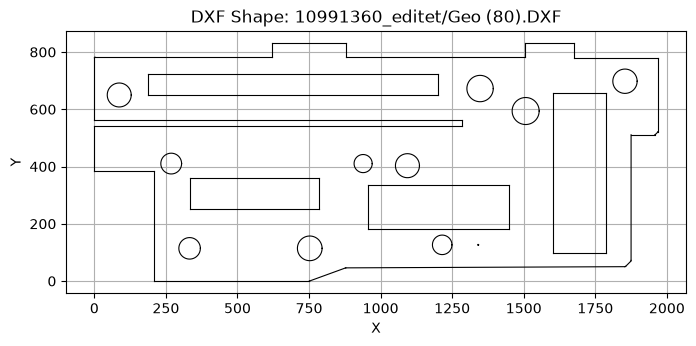

In [8]:
for i, length in enumerate(cutting_lengths):
    if (length < q1 - 1.5 * iqr) or (length > q3 + 1.5 * iqr):
        plot_dxf("10991360_editet/" + clean_data["file_name"].iloc[i])

As we see in the plots, the main drivers for the long cutting lengths are bigger geometries in general combined with an above average amount of holes.

None of the investigated geometries indicated any problems with the geometry or the function calls.

## 4. Check outliers of bounding box area

                bounding box area
q25                      15054.01
q75                     284643.81
min                        381.37
max                    2209629.28
range                  2209247.91
iqr                     269589.80
n_outliers_iqr               7.00


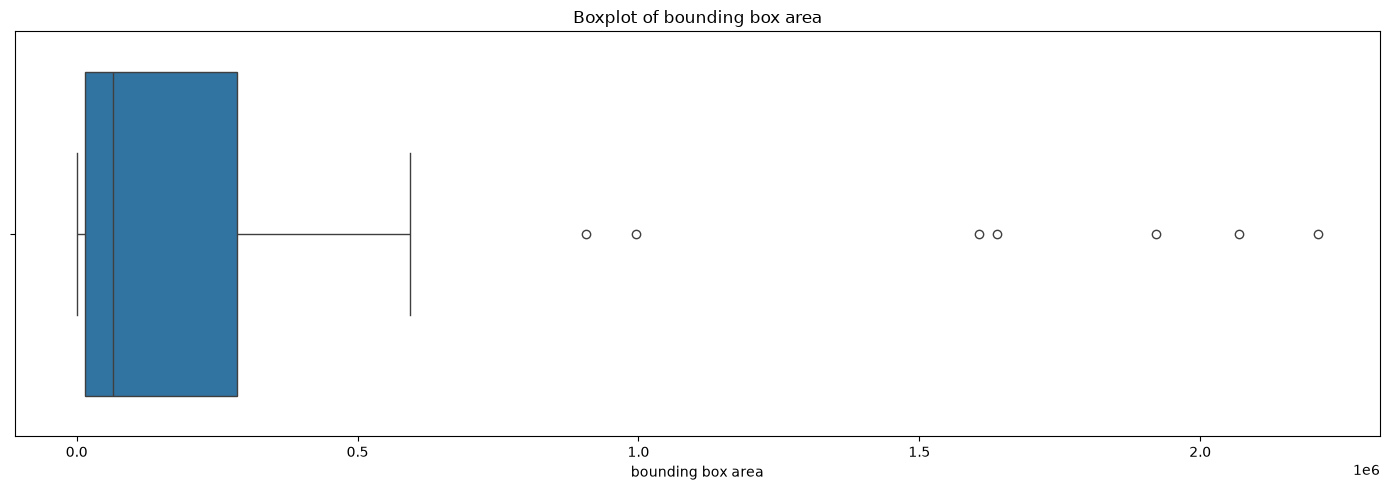

In [9]:
# Calculate area statistics
areas = clean_data["bounding_box_area"].dropna()
q1, q3 = areas.quantile(0.25), areas.quantile(0.75)
iqr = q3 - q1

area_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": areas.min(),
    "max": areas.max(),
    "range": areas.max() - areas.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((areas < q1 - 1.5 * iqr) | (areas > q3 + 1.5 * iqr)).sum(),
})

print(round(area_statistics.to_frame(name="bounding box area"), 2))


# Visualize the bounding box area statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=areas, ax=ax)
ax.set_title("Boxplot of bounding box area")
ax.set_xlabel("bounding box area")

plt.tight_layout()
plt.show()

Once again we observe quite substantially outliers (as we did for bounding box height aswell)

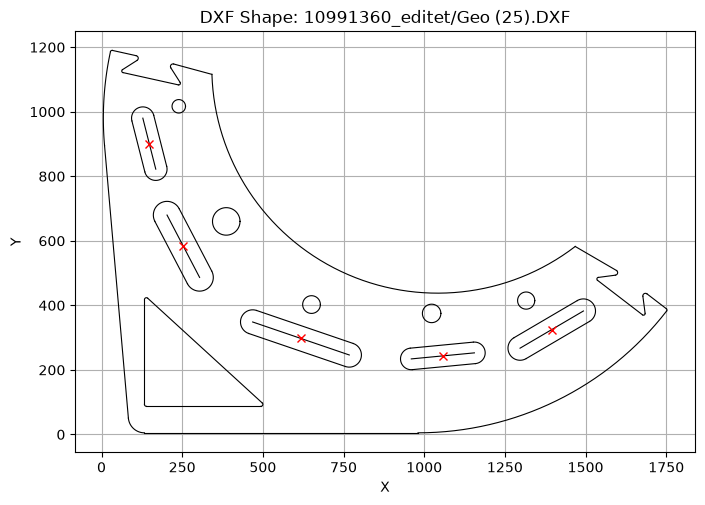

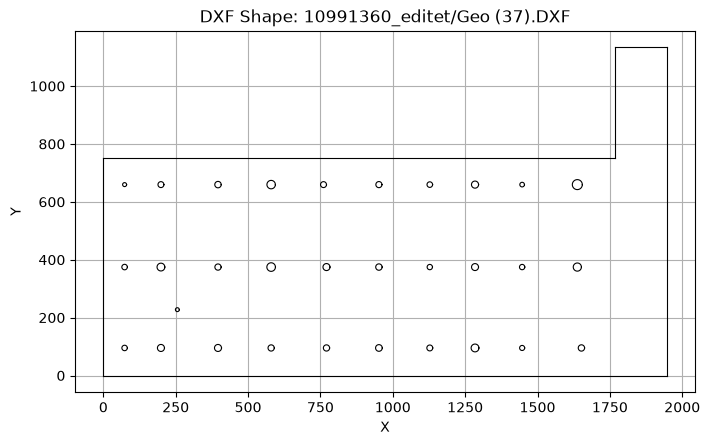

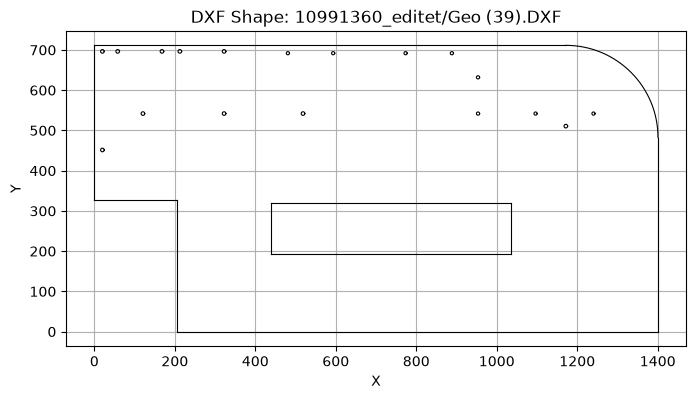

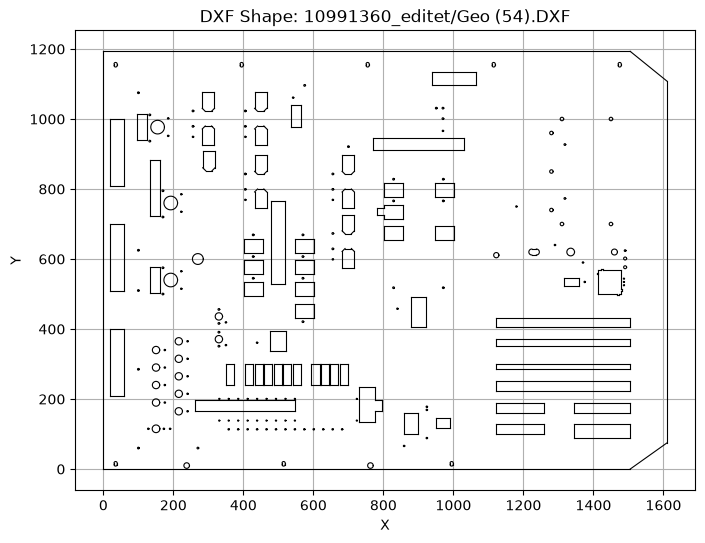

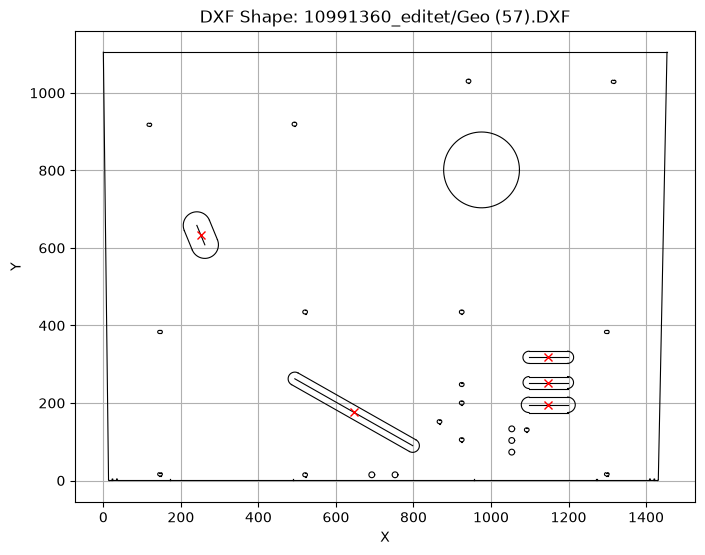

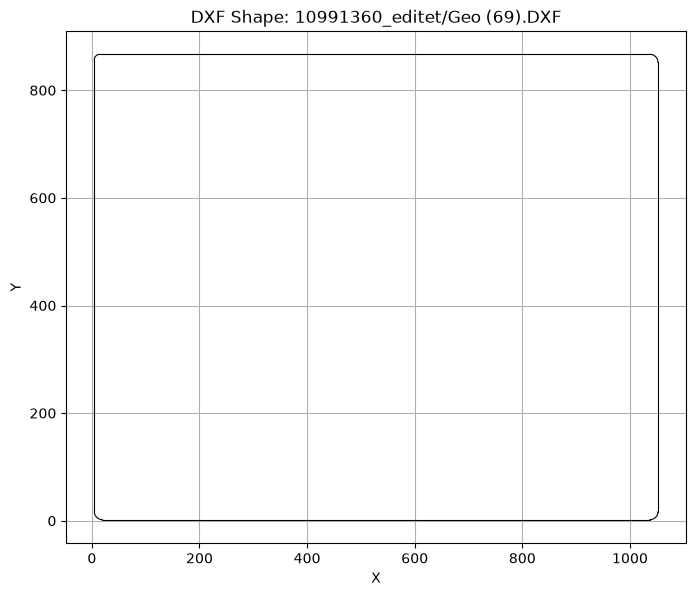

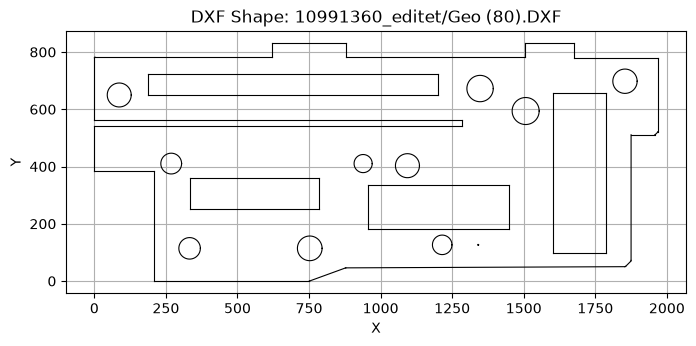

In [10]:
for i, area in enumerate(areas):
    if (area < q1 - 1.5 * iqr) or (area > q3 + 1.5 * iqr):
        plot_dxf("10991360_editet/" + clean_data["file_name"].iloc[i])

As expected the problematic DXF files are more or less the same like before, caused by the impact of bounding box height on bounding box area.

These geometries still are all correct.

## 5. Check outliers for number of holes

                number of holes
q25                         0.5
q75                         9.0
min                         0.0
max                       219.0
range                     219.0
iqr                         8.5
n_outliers_iqr              5.0


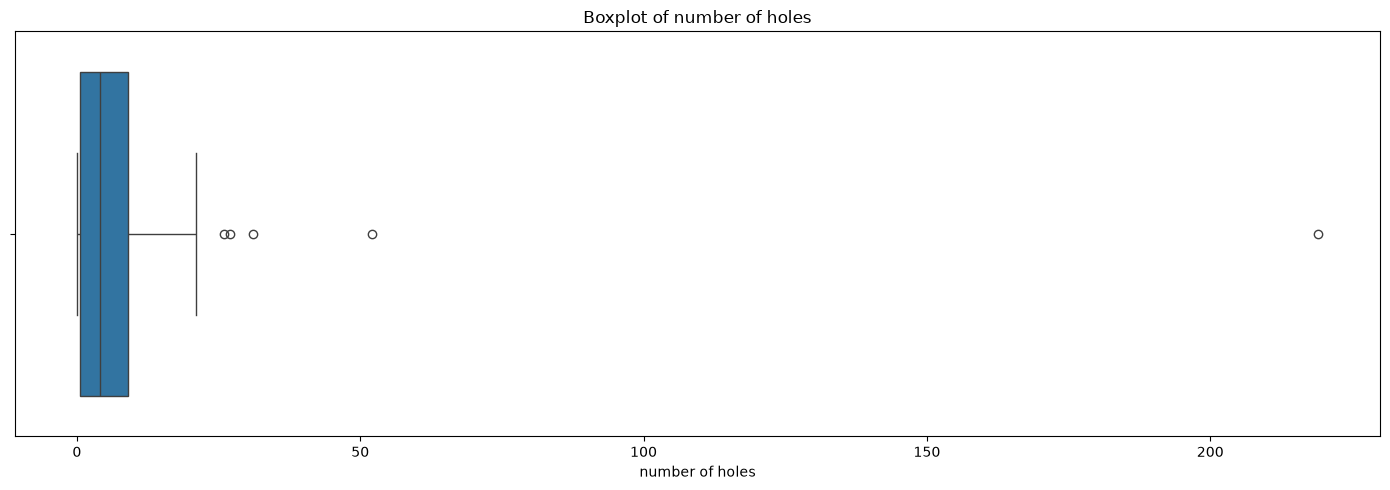

In [11]:
# Calculate hole statistics
num_holes = clean_data["num_holes"].dropna()
q1, q3 = num_holes.quantile(0.25), num_holes.quantile(0.75)
iqr = q3 - q1

num_holes_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": num_holes.min(),
    "max": num_holes.max(),
    "range": num_holes.max() - num_holes.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((num_holes < q1 - 1.5 * iqr) | (num_holes > q3 + 1.5 * iqr)).sum(),
})

print(round(num_holes_statistics.to_frame(name="number of holes"), 2))


# Visualize the hole statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=num_holes, ax=ax)
ax.set_title("Boxplot of number of holes")
ax.set_xlabel("number of holes")

plt.tight_layout()
plt.show()

For "number of holes" we have even more extrem outliers. So once again we'll check their plots to verify their correctness.

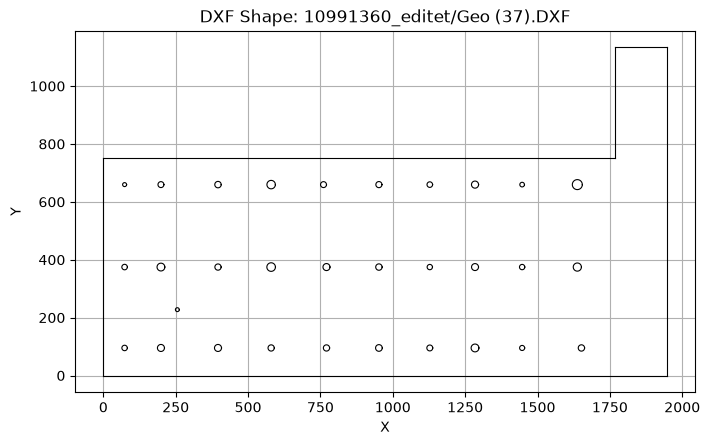

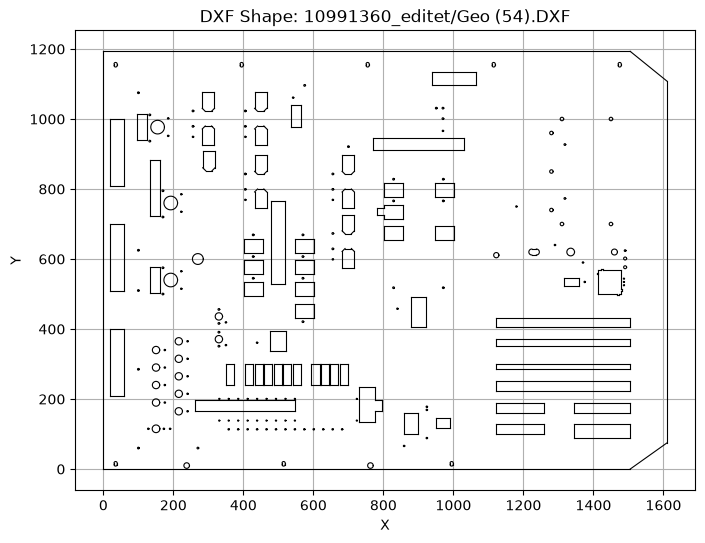

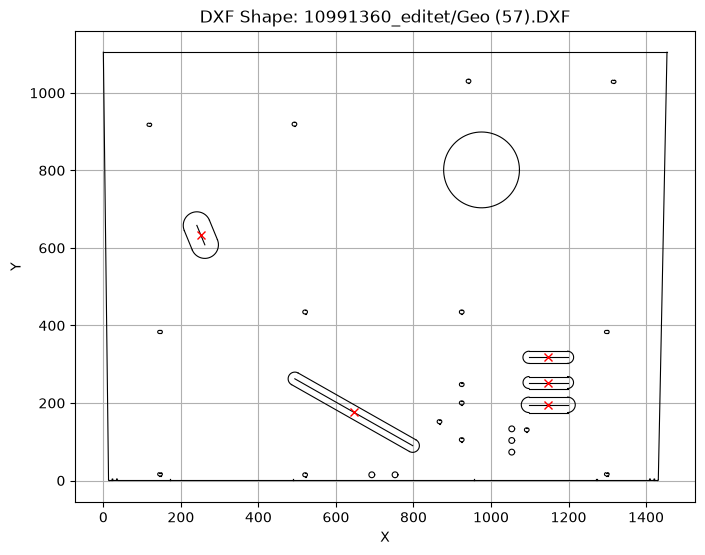

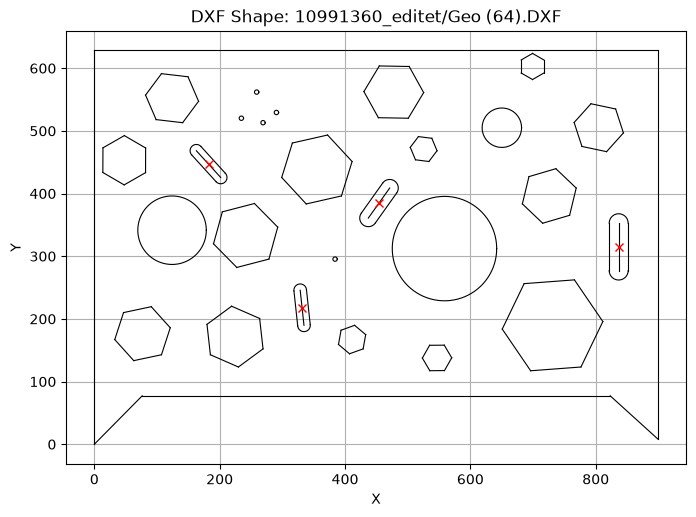

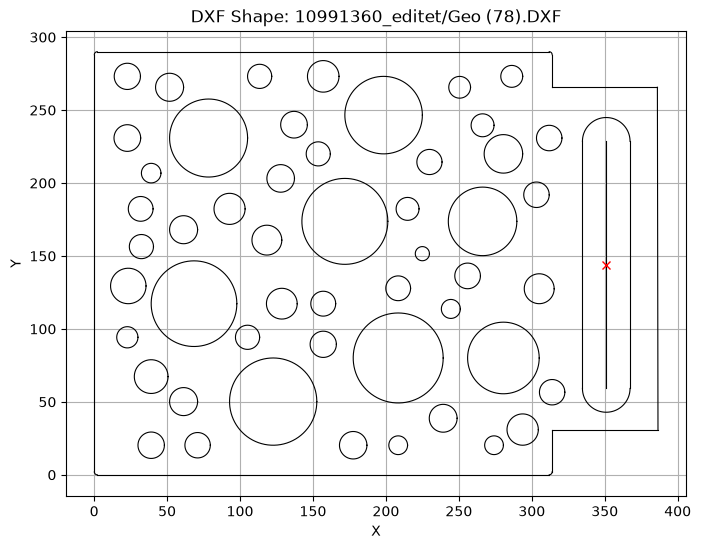

In [12]:
for i, num_hole in enumerate(num_holes):
    if (num_hole < q1 - 1.5 * iqr) or (num_hole > q3 + 1.5 * iqr):
        plot_dxf("10991360_editet/" + clean_data["file_name"].iloc[i])

These plots show, that there is a high variety in the number of holes. Especially Geo 54 is quite an outlier.

Though all plots look legit.

## 6. Check outliers of rectangularity

                rectangularity ratio
q25                             0.54
q75                             0.88
min                             0.08
max                             1.00
range                           0.92
iqr                             0.34
n_outliers_iqr                  3.00


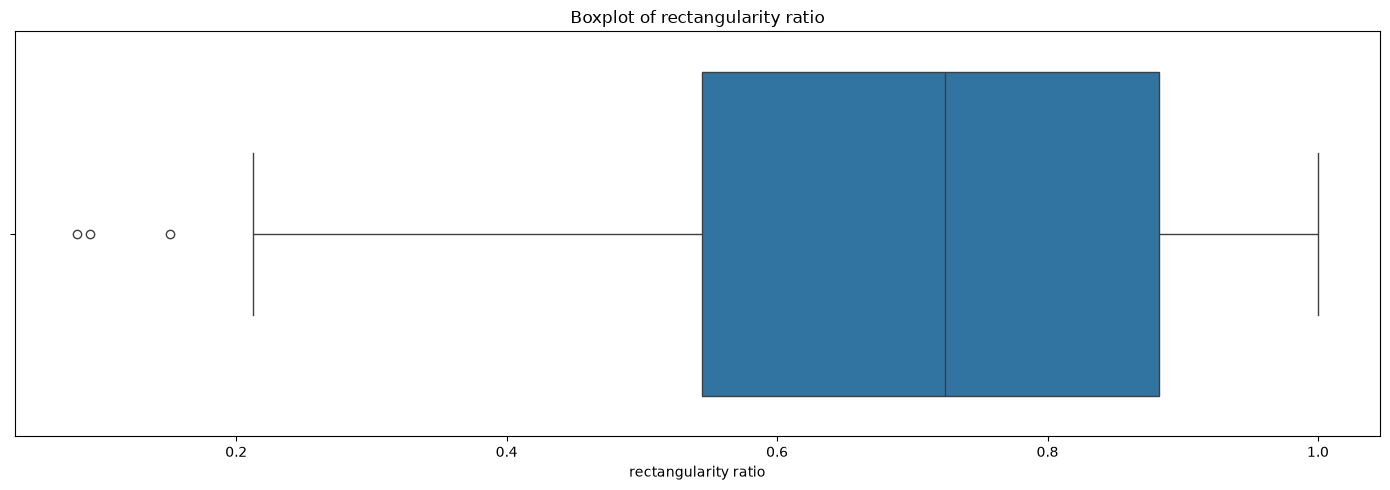

In [13]:
# Calculate rectangularity ratio statistics (whis = 1)
rectangularity_ratio = clean_data["rectangularity"].dropna()
q1, q3 = rectangularity_ratio.quantile(0.25), rectangularity_ratio.quantile(0.75)
iqr = q3 - q1

rectangularity_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": rectangularity_ratio.min(),
    "max": rectangularity_ratio.max(),
    "range": rectangularity_ratio.max() - rectangularity_ratio.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((rectangularity_ratio < q1 - iqr) | (rectangularity_ratio > q3 + iqr)).sum(),
})

print(round(rectangularity_statistics.to_frame(name="rectangularity ratio"), 2))


# Visualize the rectangularity statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=rectangularity_ratio, whis=1, ax=ax)
ax.set_title("Boxplot of rectangularity ratio")
ax.set_xlabel("rectangularity ratio")

plt.tight_layout()
plt.show()

Here we adjusted the factor for calculation the the outlier range from 1.5 to 1.

This is primarily to make smaller outliers visible, cause for whis = 1.5 no outliers would be visible at all.

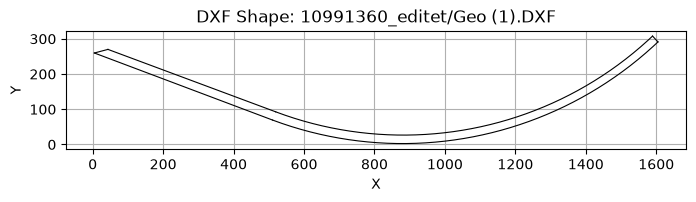

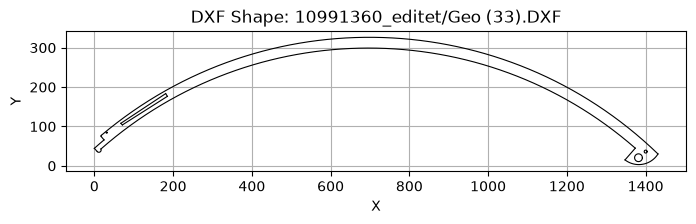

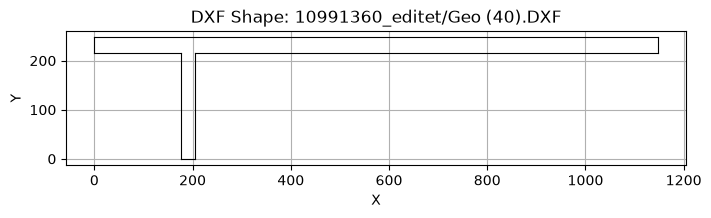

In [14]:
for i, ratio in enumerate(rectangularity_ratio):
    if (ratio < q1 - iqr) or (ratio > q3 + iqr):
        plot_dxf("10991360_editet/" + clean_data["file_name"].iloc[i])

Looking at the plots, we definitly can say that there are no problems with the geometries thereselfs. When thinking about the actual laser cutting prozess though, there is a lot of potential for optimization. Calculating the parts per sheet just by the bounding box area would cause serios inefficiencies and quite a lot of unnecessary waste.

                rectangularity ratio
q25                              1.5
q75                             10.0
min                              1.0
max                            220.0
range                          219.0
iqr                              8.5
n_outliers_iqr                   7.0


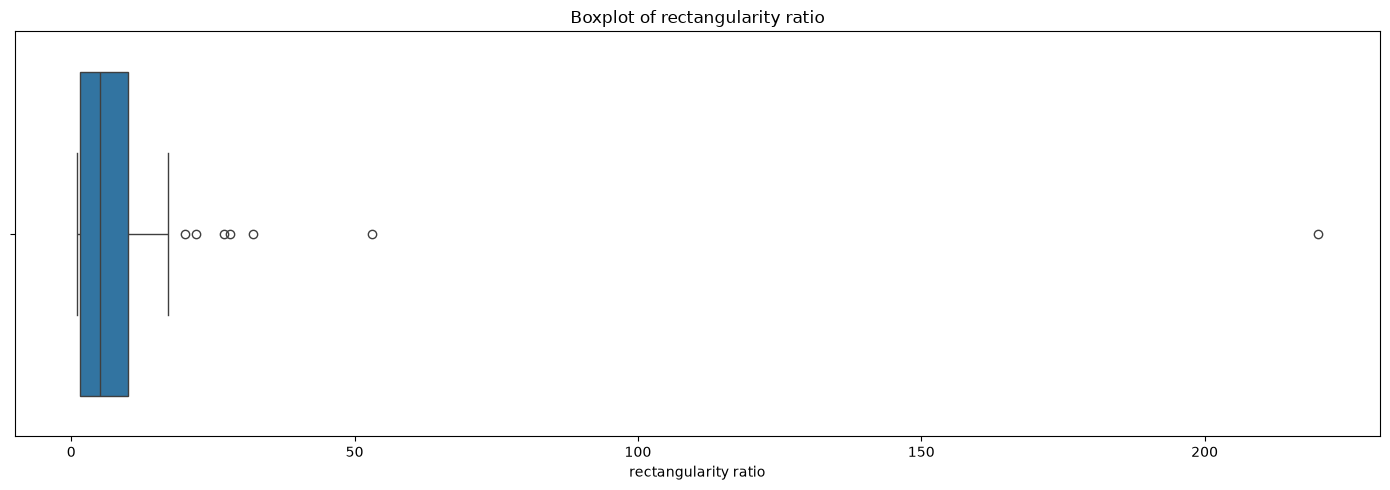

In [15]:
# Calculate pierce points statistics
num_pierce_points = clean_data["num_pierce_points"].dropna()
q1, q3 = num_pierce_points.quantile(0.25), num_pierce_points.quantile(0.75)
iqr = q3 - q1

pierce_points_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": num_pierce_points.min(),
    "max": num_pierce_points.max(),
    "range": num_pierce_points.max() - num_pierce_points.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((num_pierce_points < q1 - iqr) | (num_pierce_points > q3 + iqr)).sum(),
})

print(round(pierce_points_statistics.to_frame(name="rectangularity ratio"), 2))


# Visualize the pierce points statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=num_pierce_points, whis=1, ax=ax)
ax.set_title("Boxplot of rectangularity ratio")
ax.set_xlabel("rectangularity ratio")

plt.tight_layout()
plt.show()

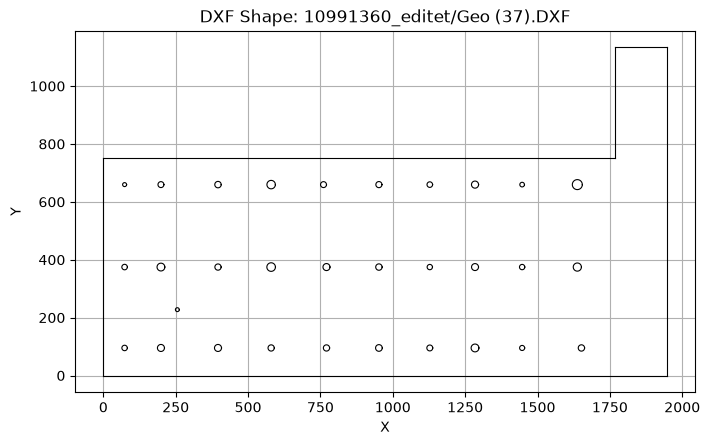

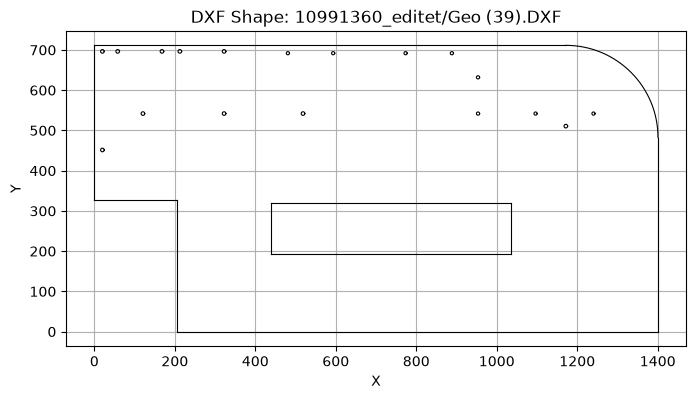

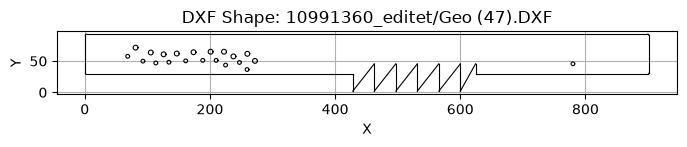

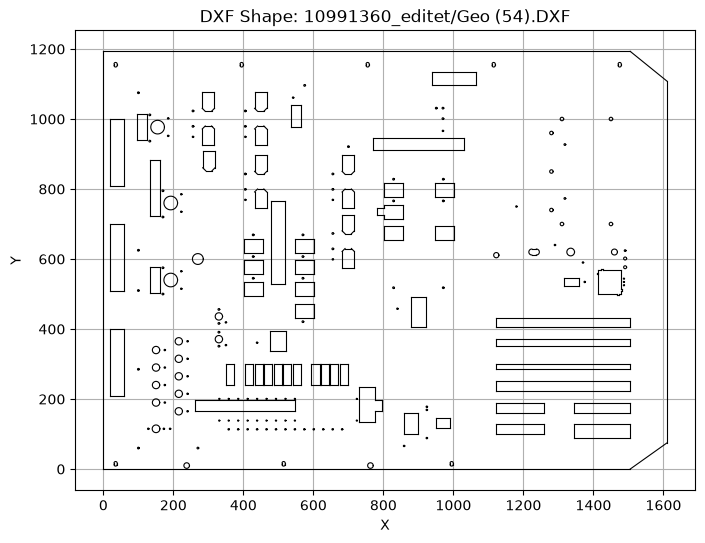

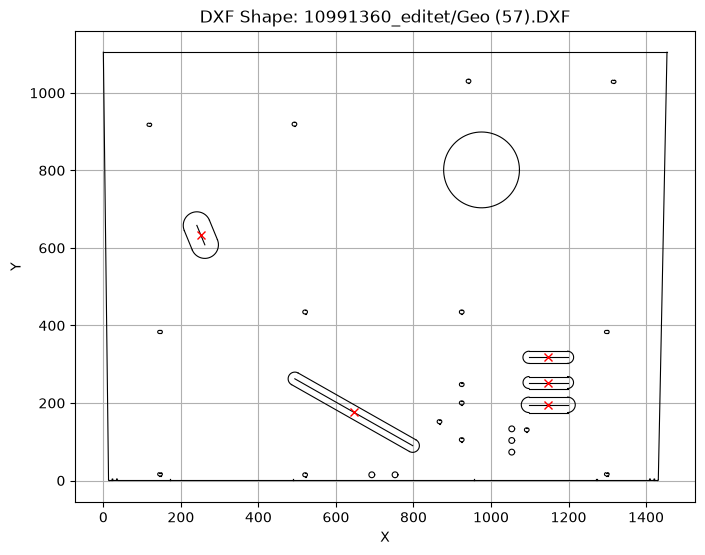

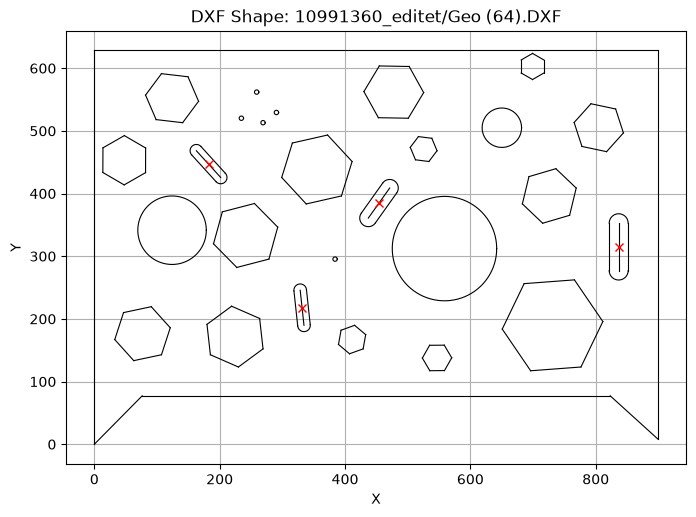

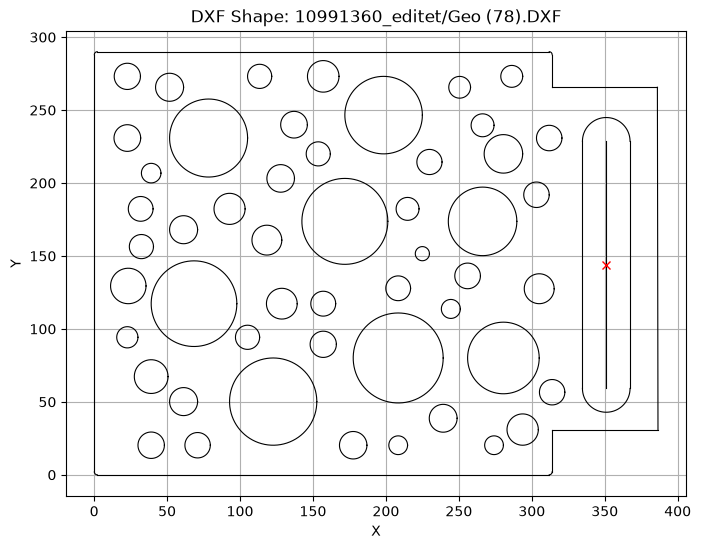

In [16]:
for i, ratio in enumerate(num_pierce_points):
    if (ratio < q1 - iqr) or (ratio > q3 + iqr):
        plot_dxf("10991360_editet/" + clean_data["file_name"].iloc[i])